# 04 - Model Comparison

Tổng hợp metrics, confusion matrix, ROC curve và lựa chọn mô hình tốt nhất. Chạy sau notebook 02 và 03 (hoặc `python main.py`).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

%matplotlib inline
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
MODELS_DIR = ROOT / "models"
MODELS_DIR.mkdir(exist_ok=True)

from src.preprocessing import prepare_data
from src.evaluation import (
    METRIC_COLUMNS, load_metrics, plot_confusion_matrix, plot_metric_comparison,
    plot_roc_curves, save_figure, select_best_model,
)

X_train, X_test, y_train, y_test = prepare_data()
models = {
    "Naive Bayes": joblib.load(MODELS_DIR / "nb_tuned.joblib"),
    "SVM": joblib.load(MODELS_DIR / "svm_tuned.joblib"),
    "Random Forest": joblib.load(MODELS_DIR / "rf_tuned.joblib"),
}

## 1. Bảng tổng hợp metrics (test set chung)

In [2]:
metrics = load_metrics()
order = {"Naive Bayes": 0, "SVM": 1, "Random Forest": 2}
metrics = metrics.sort_values(["model", "stage"], key=lambda s: s.map(order) if s.name == "model" else s).reset_index(drop=True)
metrics.style.highlight_max(subset=METRIC_COLUMNS, color="#c6efce").format(precision=4)

,model,stage,accuracy,precision,recall,f1,roc_auc
0,Naive Bayes,baseline,0.5431,0.3632,0.8638,0.5114,0.7445
1,Naive Bayes,tuned,0.6308,0.4164,0.8319,0.5550,0.7635
2,SVM,baseline,0.8098,0.7429,0.4784,0.5820,0.8559
3,SVM,tuned,0.8137,0.7095,0.5533,0.6217,0.8587
4,Random Forest,baseline,0.8379,0.7570,0.6100,0.6756,0.8904
5,Random Forest,tuned,0.8375,0.7437,0.6300,0.6822,0.8961


In [3]:
improvement = metrics.pivot(index="model", columns="stage", values=METRIC_COLUMNS)
delta = pd.DataFrame({m: improvement[(m, "tuned")] - improvement[(m, "baseline")] for m in METRIC_COLUMNS}).round(4)
delta

,accuracy,precision,recall,f1,roc_auc
model,,,,,
Naive Bayes,0.0877,0.0532,-0.0319,0.0436,0.0190
Random Forest,-0.0004,-0.0133,0.0200,0.0066,0.0057
SVM,0.0039,-0.0334,0.0749,0.0397,0.0028


## 2. Biểu đồ so sánh

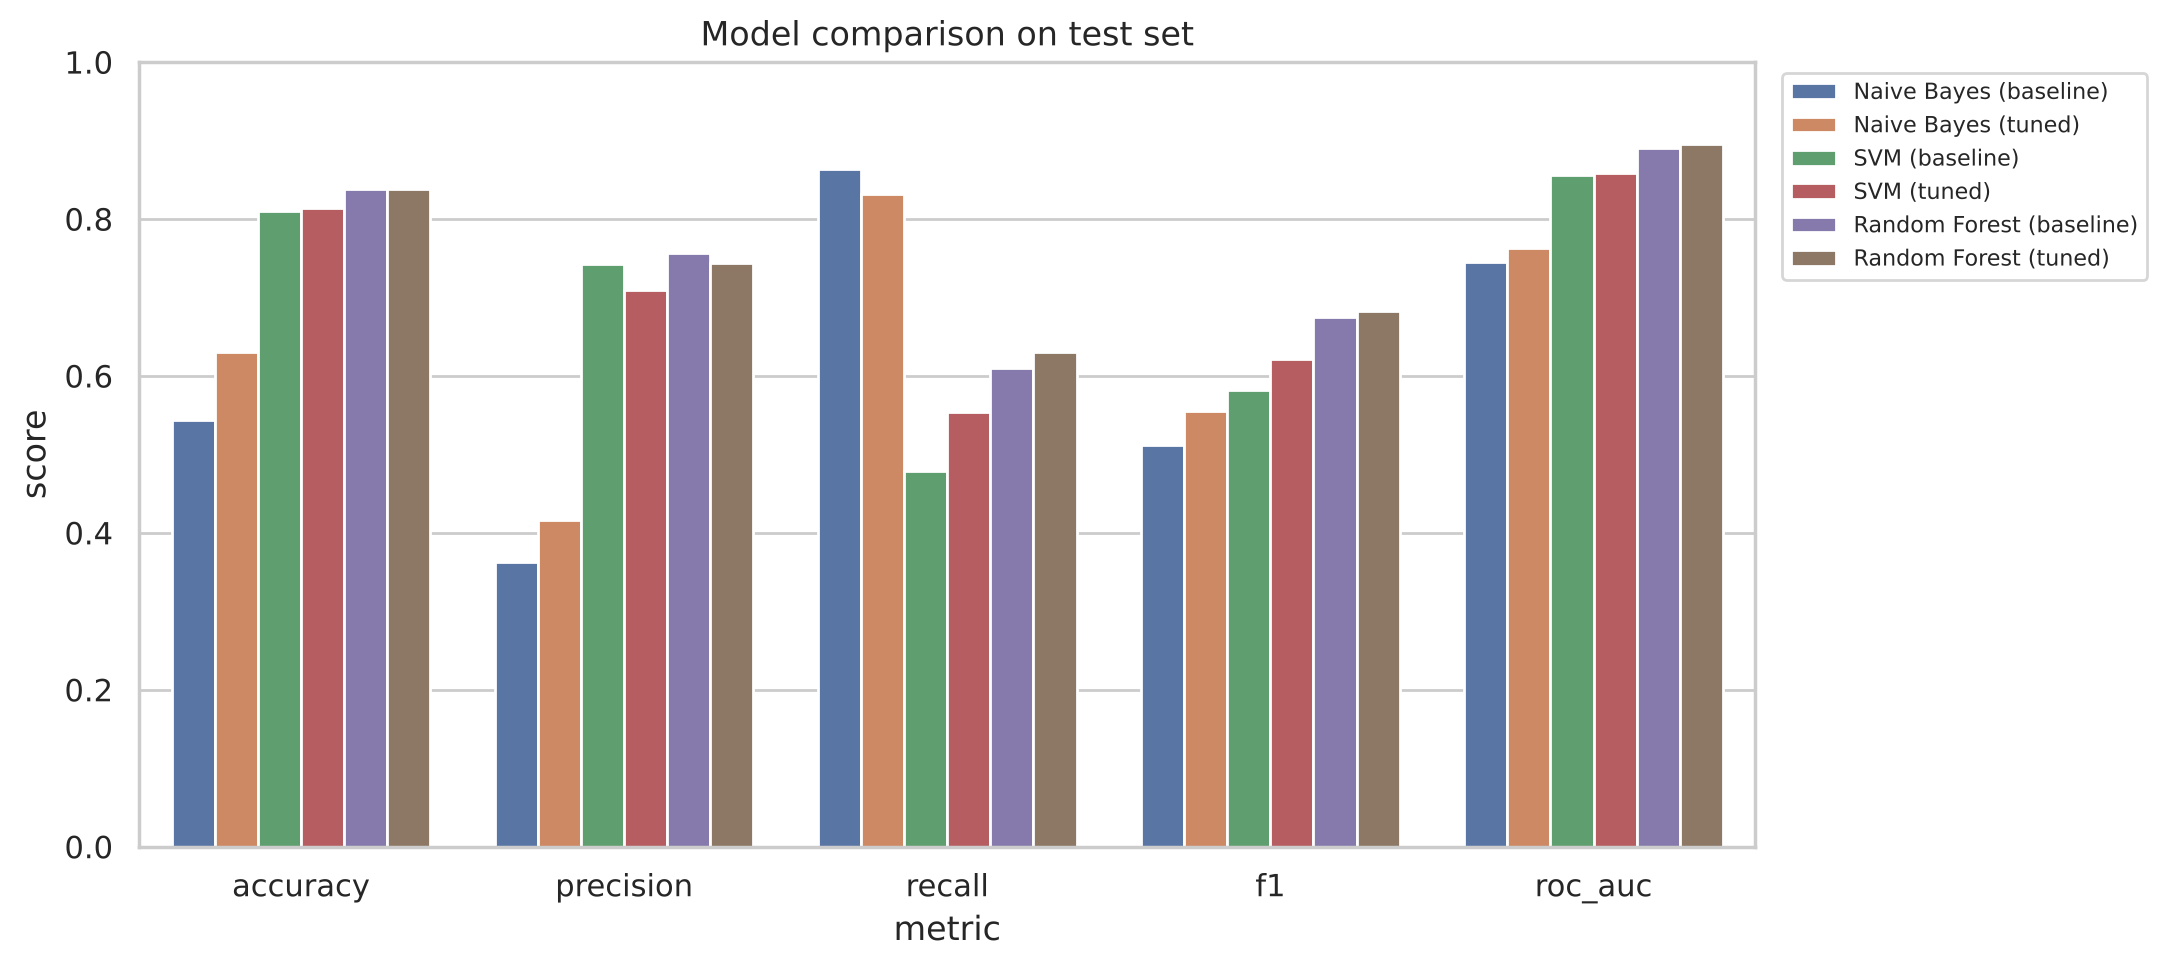

In [4]:
plot_metric_comparison(metrics, "model_comparison.png")
plt.show()

## 3. Confusion matrix

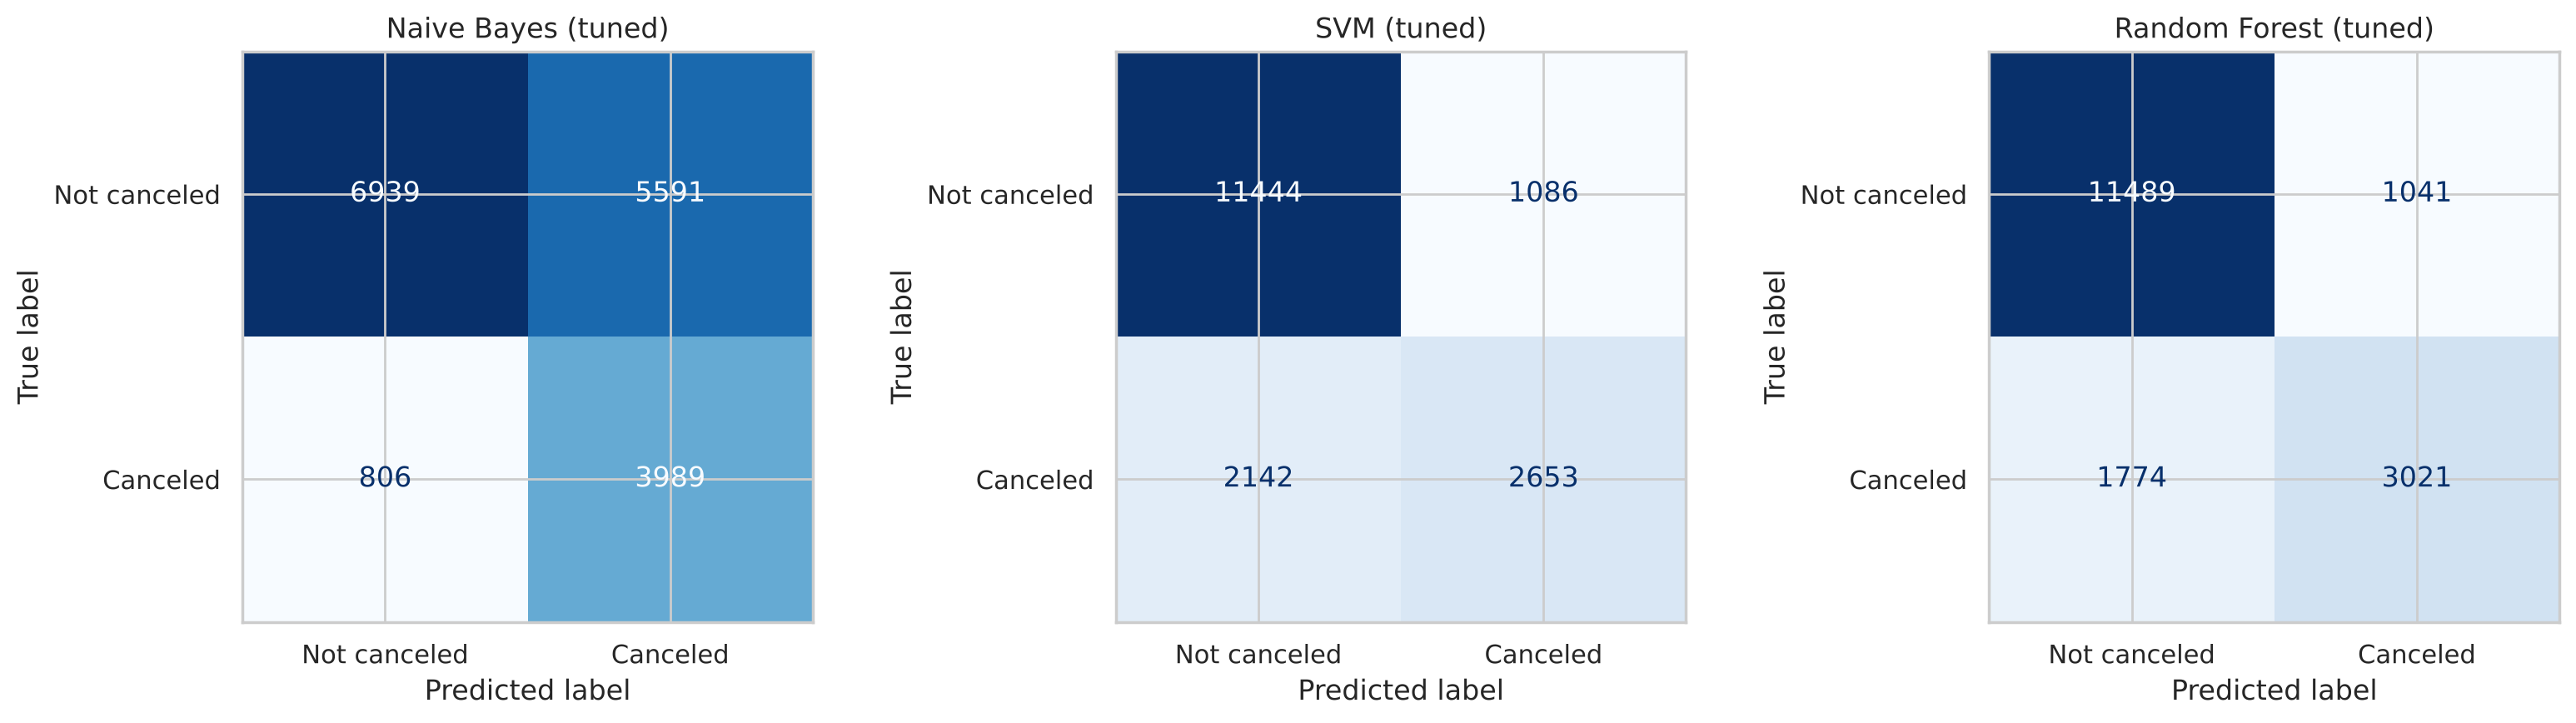

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (name, model) in zip(axes, models.items()):
    plot_confusion_matrix(model, X_test, y_test, f"{name} (tuned)", ax=ax)
save_figure(fig, "confusion_matrix_all.png")
plt.show()

## 4. ROC curve

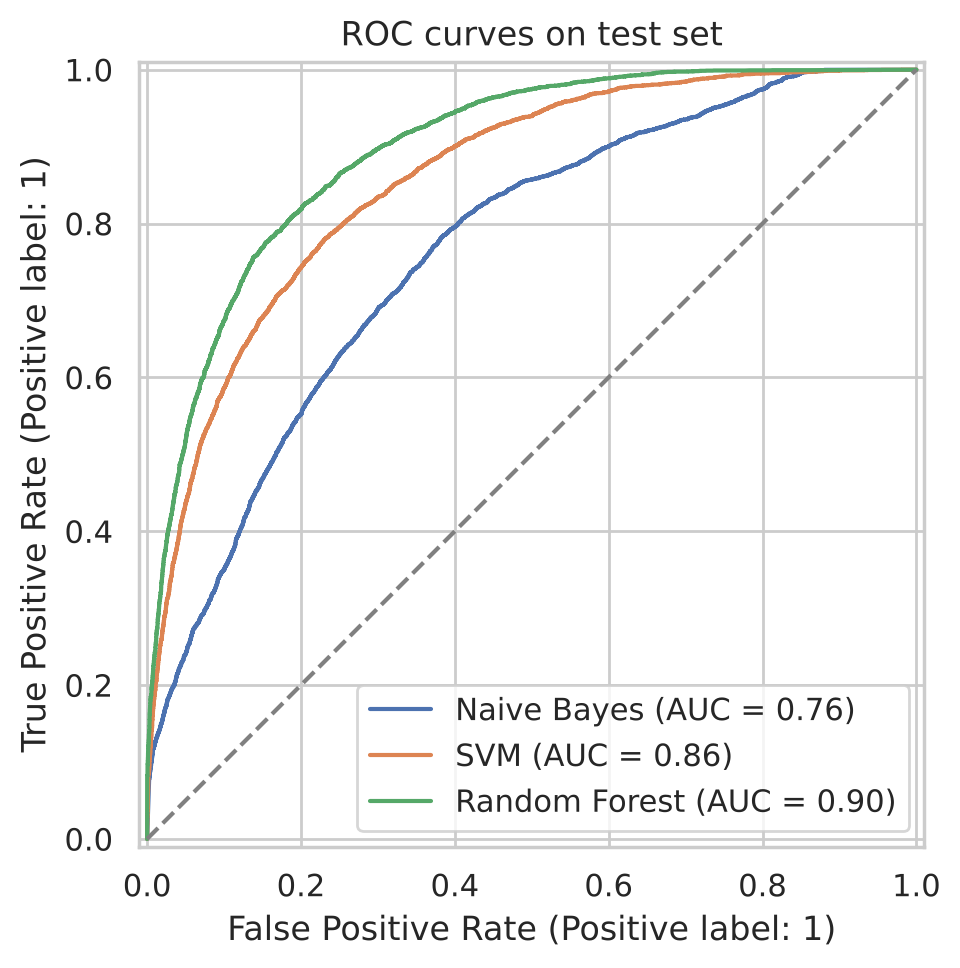

In [6]:
plot_roc_curves(models, X_test, y_test, "roc_curves.png")
plt.show()

## 5. Chọn mô hình tốt nhất

Tiêu chí chính: F1-score (cân bằng precision/recall vì dữ liệu lệch lớp), phụ: ROC-AUC.

In [7]:
tuned = metrics[metrics["stage"] == "tuned"]
best = select_best_model(tuned)
joblib.dump(models[best["model"]], MODELS_DIR / "best_model.joblib")
print(f"Mô hình tốt nhất: {best['model']}")
best[METRIC_COLUMNS]

Mô hình tốt nhất: Random Forest


accuracy     0.8375
precision    0.7437
recall         0.63
f1           0.6822
roc_auc      0.8961
Name: 5, dtype: object

## 6. Kết luận

- **Random Forest** cho kết quả tốt nhất trên mọi metric chính (F1, ROC-AUC, accuracy), nhờ khả năng học quan hệ phi tuyến và tương tác giữa các đặc trưng như `lead_time`, `deposit_type`, `country`.
- **SVM** đứng thứ hai, precision khá nhưng recall thấp hơn; chi phí train lớn nên phải train trên mẫu con.
- **Naive Bayes** nhanh nhưng giả định độc lập không phù hợp với dữ liệu, cho nhiều false positive.
- Tuning cải thiện cả 3 mô hình so với baseline.
- Mô hình tốt nhất được lưu tại `models/best_model.joblib`, dùng bằng `python predict.py`.